In [1]:
!pip install catboost xgboost lightgbm gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 39.6 MB/s  0:00:02


# Task 05 — Bank Marketing (Classification)
**Goal:** predict whether a client will subscribe to a term deposit. **Target:** `deposit` (yes / no). **Features:** age, job, marital, education, default, balance, housing, loan, contact, day, month, campaign, pdays, previous, poutcome.

The classes are almost balanced (about 47% yes), so Accuracy is meaningful here, but we still report Precision, Recall, F1, ROC-AUC and PR-AUC.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

## 1. Load the data

In [3]:
import os
path = 'dataset/bank.csv'
if not os.path.exists(path):          # e.g. file uploaded next to the notebook (Colab)
    path = 'bank.csv'
df = pd.read_csv(path)

In [4]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


In [5]:
df.shape

(8912, 17)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   object 
 2   marital    8743 non-null   object 
 3   education  8885 non-null   object 
 4   default    8908 non-null   object 
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   object 
 7   loan       8882 non-null   object 
 8   contact    8881 non-null   object 
 9   day        8893 non-null   float64
 10  month      8884 non-null   object 
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   object 
 16  deposit    8903 non-null   object 
dtypes: float64(6), int64(1), object(10)
memory usage: 1.2+ MB


In [7]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8909.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.834325
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.304733
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


In [8]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'deposit'],
      dtype='object')

## 2. Data cleaning

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df.drop_duplicates()

In [11]:
df.isnull().sum()

,0
age,0
job,7
marital,169
education,27
default,4
balance,13
housing,13
loan,30
contact,31
day,19


In [12]:
df = df.dropna(subset=['deposit'])

**Data leakage:** `duration` (call length) is known only after the call ends, and long calls almost always end in "yes". A model that uses it looks great but cannot be used before calling the client, so it is removed. Rows without a target are removed (the target is never filled).

In [13]:
# 'duration' (length of the last call) is only known AFTER the call, when the answer is already known.
# It cannot be used to predict in real life (data leakage), so it is removed.
X = df.drop(columns=['deposit', 'duration'])
y = df['deposit']

In [14]:
cat_cols = X.select_dtypes(include=['object']).columns
num_cols = X.select_dtypes(include=['number']).columns

**Missing values:** categorical ones become the category `unknown`; the numeric ones (age, balance, day, campaign, pdays, previous) are filled after the split with the median of the train data only.

In [15]:
# Categorical missing values -> the category 'unknown' (this dataset already uses 'unknown' for this).
# It is a fixed rule that learns nothing from the data, so it is safe before the split.
for col in cat_cols:
    X[col] = X[col].fillna('unknown')

In [16]:
# numeric columns still have a few missing values: they are filled AFTER the split (train median only)
missing = X.isnull().sum()
print(missing[missing > 0])

balance      13
day          19
campaign      8
pdays       136
previous      3
dtype: int64


## 3. EDA (visualization)

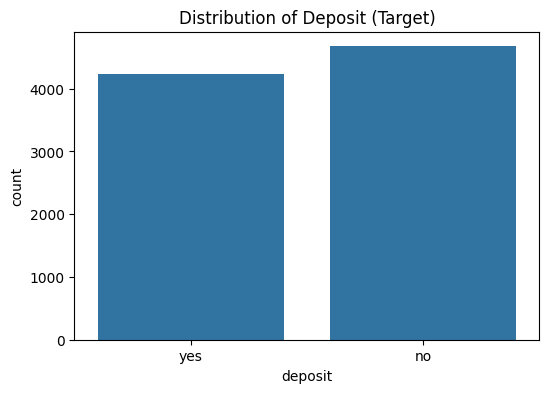

In [17]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title('Distribution of Deposit (Target)')
plt.show()

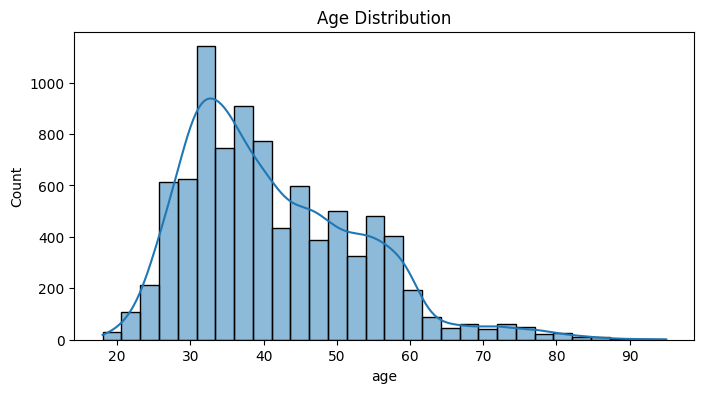

In [18]:
plt.figure(figsize=(8, 4))
sns.histplot(X['age'], kde=True, bins=30)
plt.title('Age Distribution')
plt.show()

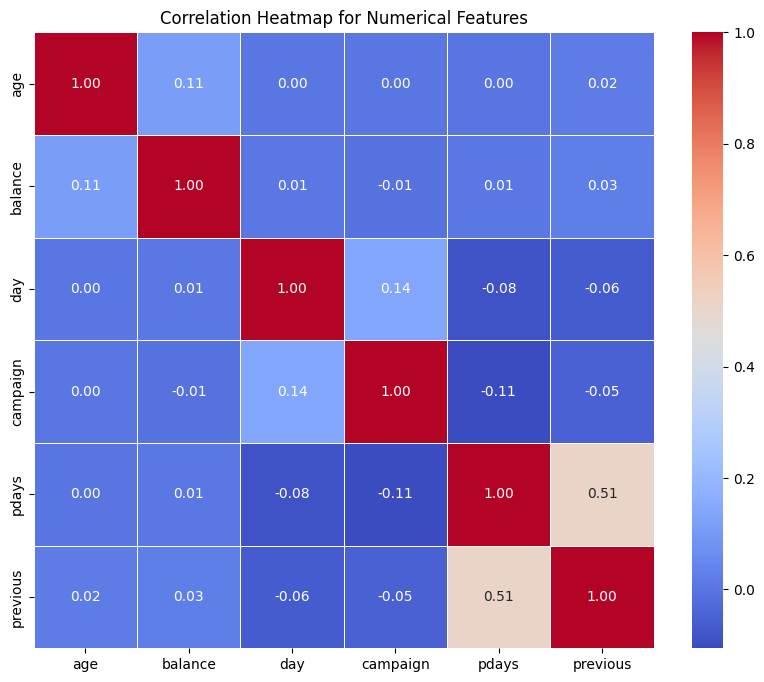

In [19]:
plt.figure(figsize=(10, 8))
numeric_df = X.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap for Numerical Features')
plt.show()

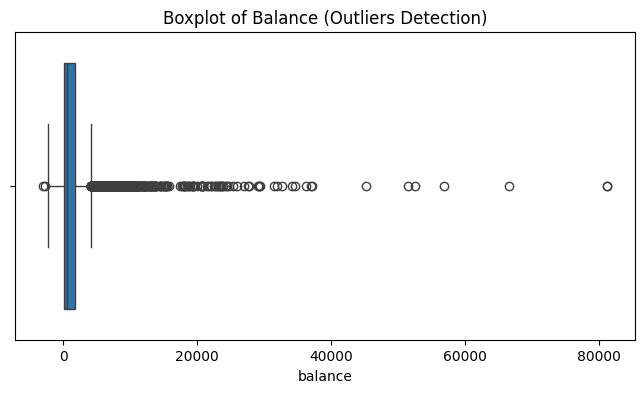

In [20]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=X['balance'])
plt.title('Boxplot of Balance (Outliers Detection)')
plt.show()

### Outliers (IQR rule)

In [21]:
for col in ['age', 'balance', 'campaign', 'pdays', 'previous']:
    q1, q3 = X[col].quantile(0.25), X[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((X[col] < low) | (X[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out / len(X) * 100:.1f}%)  [valid range {low:.0f} to {high:.0f}]  min = {X[col].min():.0f}, max = {X[col].max():.0f}")

age: 128 outliers (1.4%)  [valid range 6 to 74]  min = 18, max = 95
balance: 839 outliers (9.4%)  [valid range -2287 to 4136]  min = -3058, max = 81204
campaign: 472 outliers (5.3%)  [valid range -2 to 6]  min = 1, max = 63
pdays: 1414 outliers (15.9%)  [valid range -98 to 162]  min = -1, max = 842
previous: 1003 outliers (11.3%)  [valid range -2 to 2]  min = 0, max = 58


**Decision:** the outliers are **kept**. A very high `balance` is a real rich client, a high `campaign` / `previous` is a client contacted many times, and `pdays = -1` means "never contacted before" (a code, not an error). Deleting them would remove real information; the scaling used below and the tree models handle large values well.

## 4. Encoding

In [22]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)

print("Shape after encoding:", X_encoded.shape)

Shape after encoding: (8903, 46)


## 5. Train / Test split
Stratified split: the share of yes / no stays the same in train and test.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (7122, 46)
X_test shape: (1781, 46)


### Fill missing numeric values (median of the train data only, then applied to test) -> no data leakage

In [24]:
from sklearn.impute import SimpleImputer

X_train = X_train.copy()
X_test = X_test.copy()

num_cols = list(num_cols)
imputer_num = SimpleImputer(strategy='median')
X_train[num_cols] = imputer_num.fit_transform(X_train[num_cols])
X_test[num_cols] = imputer_num.transform(X_test[num_cols])

print("Missing values left:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

Missing values left: 0 0


## 6. Scaling (fit on train only)

In [25]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
# use the scaled data for ALL the models below (KNN, SVM, Logistic Regression need scaling)
X_train = pd.DataFrame(X_train_scaled, columns=X_encoded.columns, index=X_train.index)
X_test = pd.DataFrame(X_test_scaled, columns=X_encoded.columns, index=X_test.index)

## 7. First models

In [27]:
print("Class distribution in y_train:", np.bincount(y_train))

Class distribution in y_train: [3738 3384]


In [28]:

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Naive Bayes': GaussianNB()
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    results.append({
        'Model': name,
        'Accuracy': f"{acc*100:.2f}%"
    })

    print(f"=== {name} ===")
    print(f"Accuracy: {acc:.4f}")
    print("Confusion Matrix:\n", cm)
    print("Classification Report:\n", classification_report(y_test, y_pred))
    print("-" * 40)


metrics_table = pd.DataFrame(results)
print("\n--- Final Metrics Table ---")
print(metrics_table)

=== Logistic Regression ===
Accuracy: 0.7114
Confusion Matrix:
 [[752 183]
 [331 515]]
Classification Report:
               precision    recall  f1-score   support

           0       0.69      0.80      0.75       935
           1       0.74      0.61      0.67       846

    accuracy                           0.71      1781
   macro avg       0.72      0.71      0.71      1781
weighted avg       0.72      0.71      0.71      1781

----------------------------------------
=== KNN ===
Accuracy: 0.6968
Confusion Matrix:
 [[714 221]
 [319 527]]
Classification Report:
               precision    recall  f1-score   support

           0       0.69      0.76      0.73       935
           1       0.70      0.62      0.66       846

    accuracy                           0.70      1781
   macro avg       0.70      0.69      0.69      1781
weighted avg       0.70      0.70      0.70      1781

----------------------------------------
=== Naive Bayes ===
Accuracy: 0.5969
Confusion Matrix:
 [[

In [29]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
svc_model = SVC(C=1, kernel='rbf', gamma='scale')
svc_model.fit(X_train_scaled, y_train)

grid_params = {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}
grid = GridSearchCV(estimator=SVC(), param_grid=grid_params, cv=3, scoring='accuracy')
grid.fit(X_train_scaled, y_train)

best_svc = grid.best_estimator_
print("Best SVC Accuracy:", accuracy_score(y_test, best_svc.predict(X_test_scaled)))

Best SVC Accuracy: 0.7372262773722628


**Note:** the grid above chooses by Accuracy and prints the test accuracy. It is only a first look; the model selection below uses cross-validation on the training data only.

## 8. All the models
All models of the track are trained on the scaled data and evaluated on the test set (confusion matrix, classification report, ROC curve, PR curve).

In [30]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[752 183]
 [331 515]]


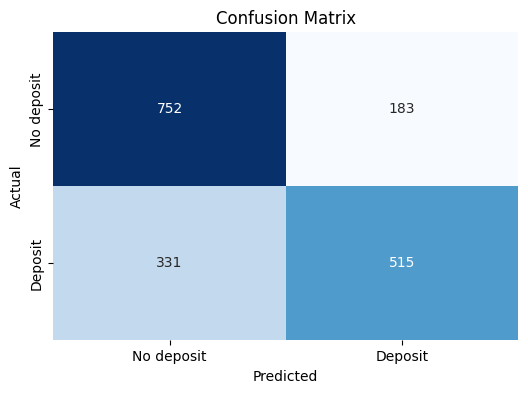


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.69      0.80      0.75       935
     Deposit       0.74      0.61      0.67       846

    accuracy                           0.71      1781
   macro avg       0.72      0.71      0.71      1781
weighted avg       0.72      0.71      0.71      1781

ROC-AUC: 0.7753580864970101


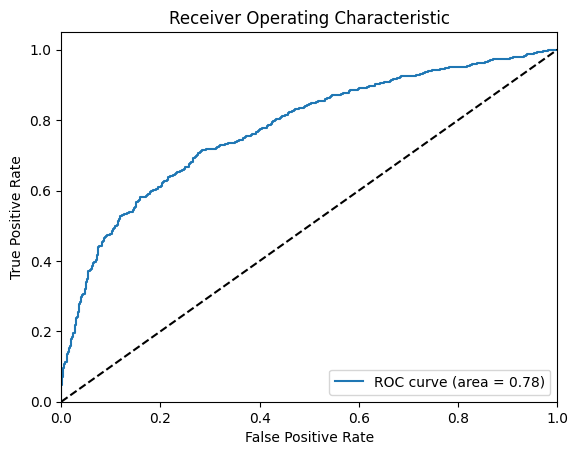

PR AUC: 0.7702345105352298


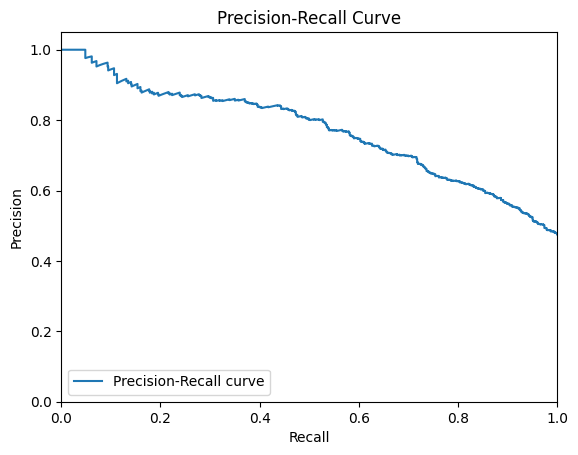

  8%|▊         | 1/13 [00:00<00:07,  1.56it/s]


Confusion Matrix:
 [[714 221]
 [319 527]]


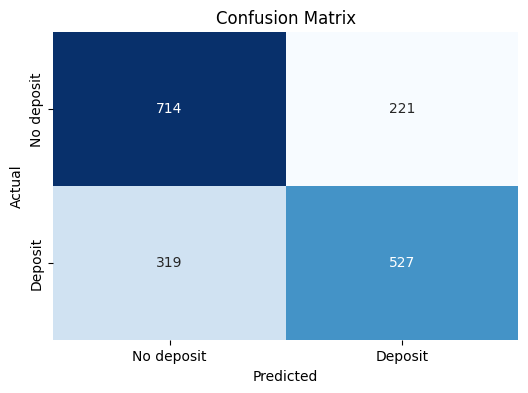


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.69      0.76      0.73       935
     Deposit       0.70      0.62      0.66       846

    accuracy                           0.70      1781
   macro avg       0.70      0.69      0.69      1781
weighted avg       0.70      0.70      0.70      1781

ROC-AUC: 0.7397801544860367


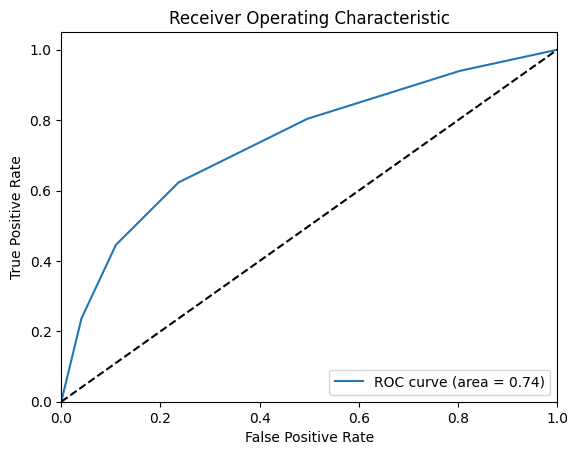

PR AUC: 0.6939409552582677


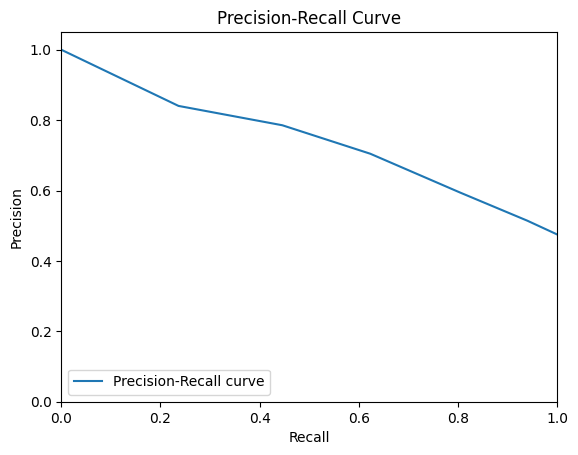

 15%|█▌        | 2/13 [00:02<00:15,  1.43s/it]


Confusion Matrix:
 [[807 128]
 [340 506]]


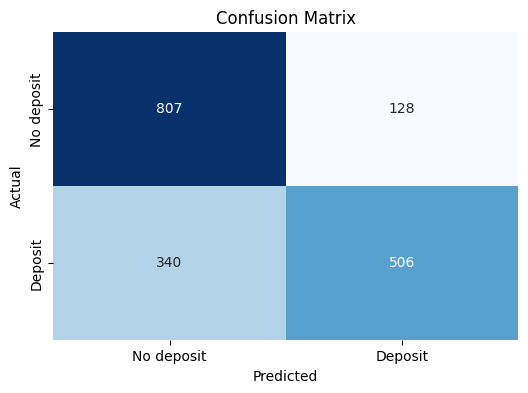


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.70      0.86      0.78       935
     Deposit       0.80      0.60      0.68       846

    accuracy                           0.74      1781
   macro avg       0.75      0.73      0.73      1781
weighted avg       0.75      0.74      0.73      1781

ROC-AUC: 0.7786936954020809


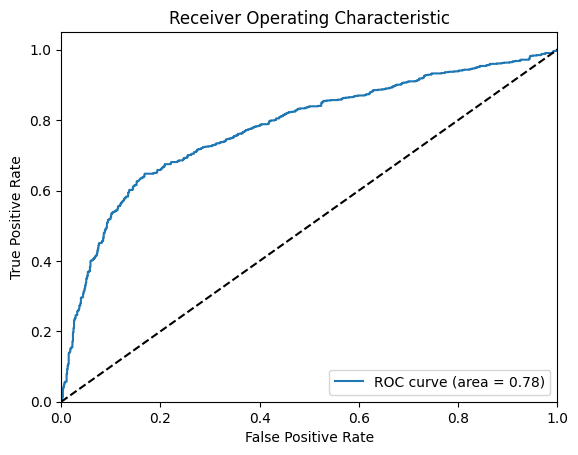

PR AUC: 0.7668715564519942


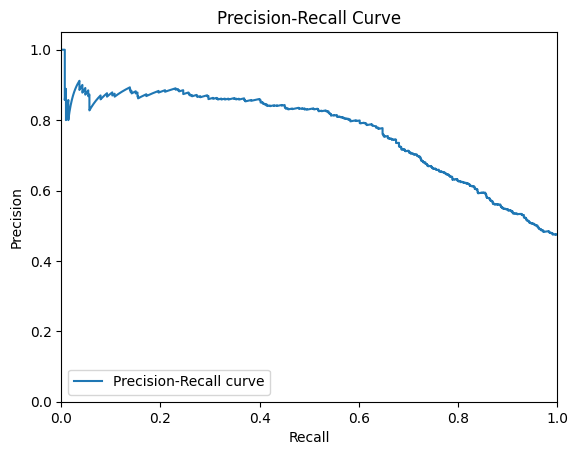

 23%|██▎       | 3/13 [00:27<02:00, 12.08s/it]


Confusion Matrix:
 [[602 333]
 [312 534]]


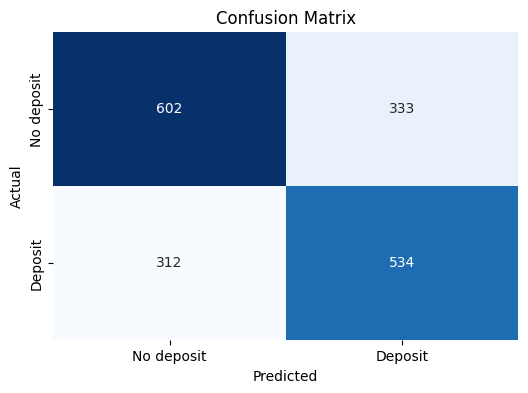


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.66      0.64      0.65       935
     Deposit       0.62      0.63      0.62       846

    accuracy                           0.64      1781
   macro avg       0.64      0.64      0.64      1781
weighted avg       0.64      0.64      0.64      1781

ROC-AUC: 0.6375279705692721


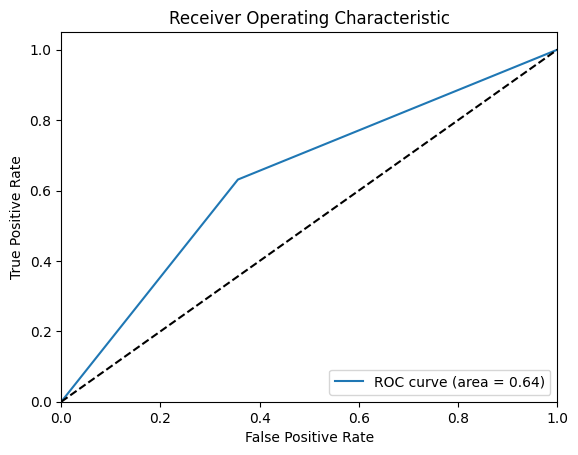

PR AUC: 0.563952758323029


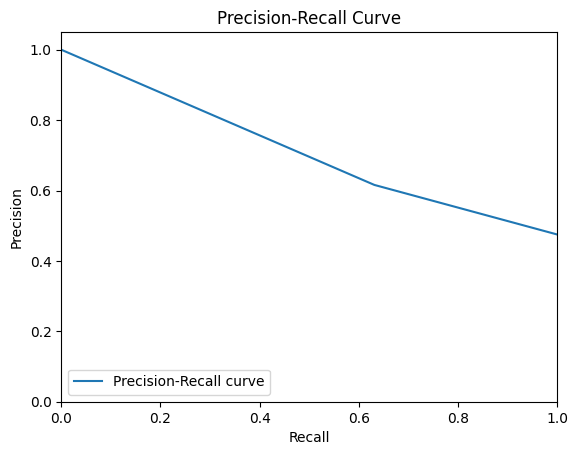

 31%|███       | 4/13 [00:27<01:08,  7.56s/it]


Confusion Matrix:
 [[914  21]
 [697 149]]


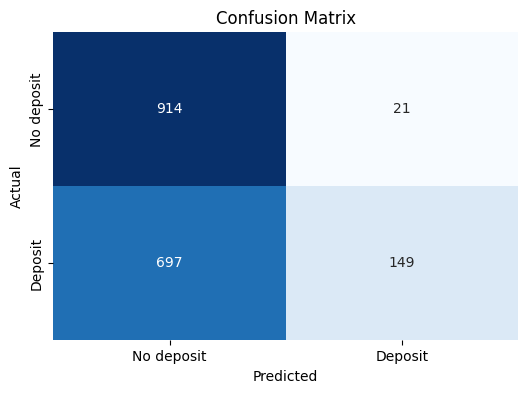


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.57      0.98      0.72       935
     Deposit       0.88      0.18      0.29       846

    accuracy                           0.60      1781
   macro avg       0.72      0.58      0.51      1781
weighted avg       0.71      0.60      0.52      1781

ROC-AUC: 0.7416663506150365


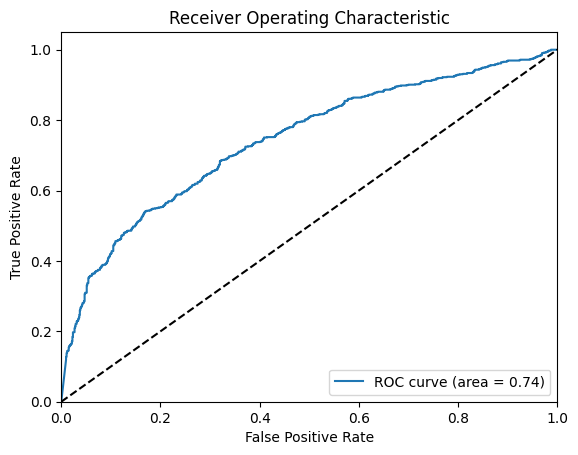

PR AUC: 0.7375544717990583


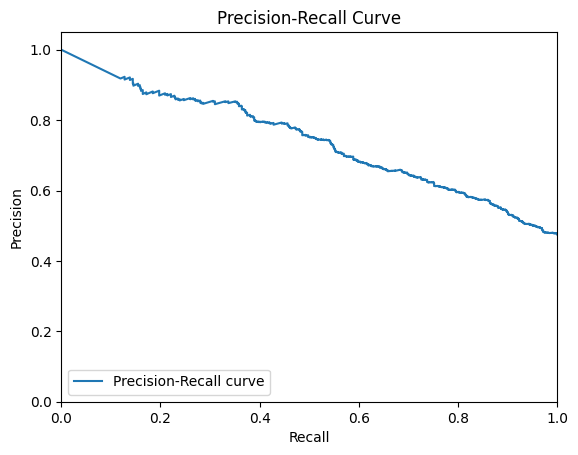

 38%|███▊      | 5/13 [00:28<00:40,  5.08s/it]


Confusion Matrix:
 [[737 198]
 [289 557]]


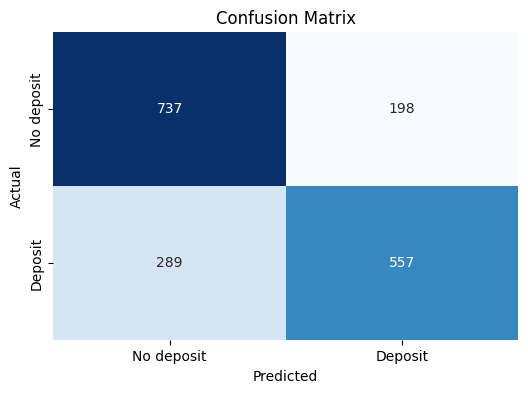


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.72      0.79      0.75       935
     Deposit       0.74      0.66      0.70       846

    accuracy                           0.73      1781
   macro avg       0.73      0.72      0.72      1781
weighted avg       0.73      0.73      0.73      1781

ROC-AUC: 0.7845735199302158


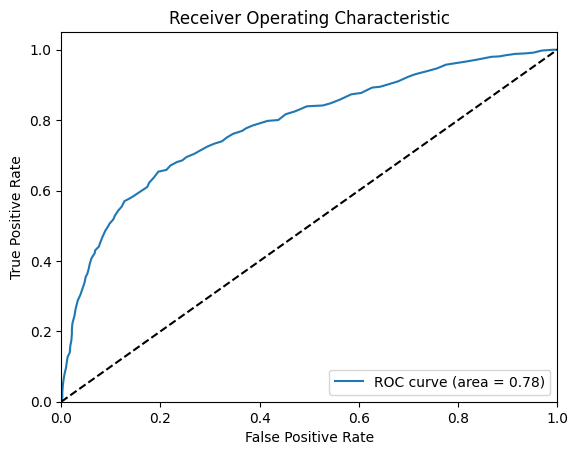

PR AUC: 0.7723747160626061


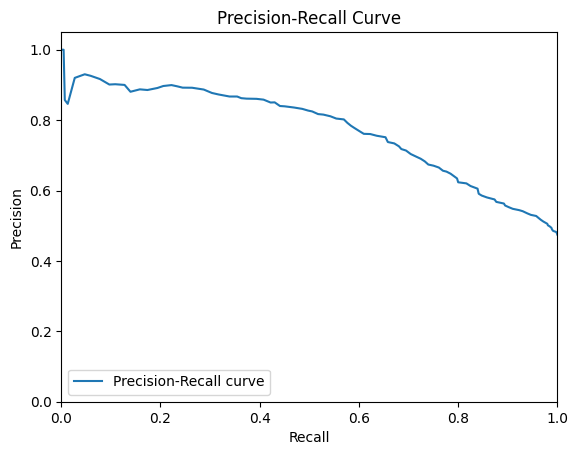

 46%|████▌     | 6/13 [00:31<00:29,  4.28s/it]


Confusion Matrix:
 [[703 232]
 [300 546]]


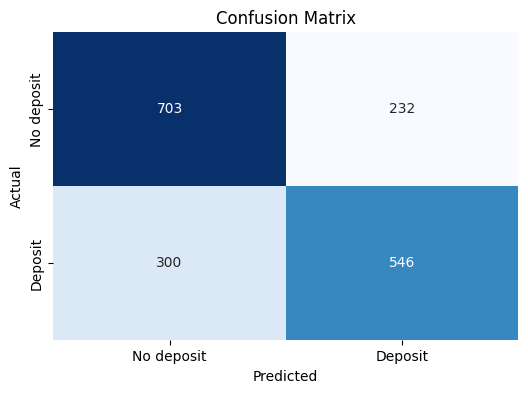


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.70      0.75      0.73       935
     Deposit       0.70      0.65      0.67       846

    accuracy                           0.70      1781
   macro avg       0.70      0.70      0.70      1781
weighted avg       0.70      0.70      0.70      1781

ROC-AUC: 0.7609998609372828


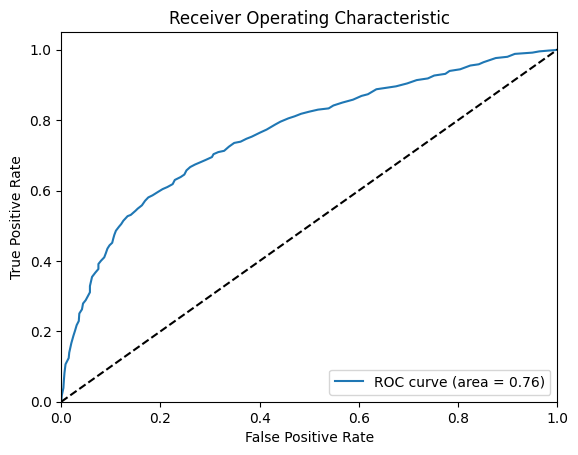

PR AUC: 0.7473399816292527


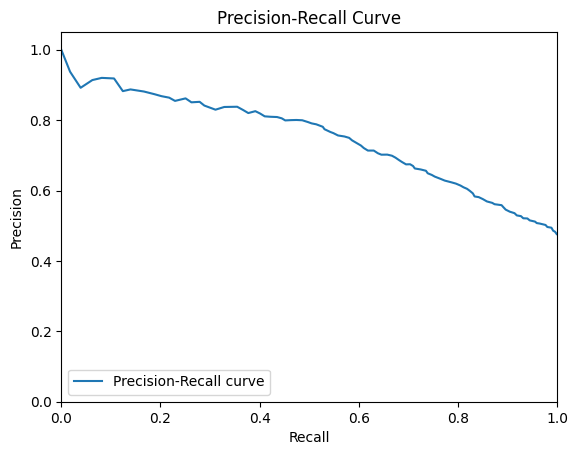

 54%|█████▍    | 7/13 [00:33<00:21,  3.53s/it]


Confusion Matrix:
 [[627 308]
 [264 582]]


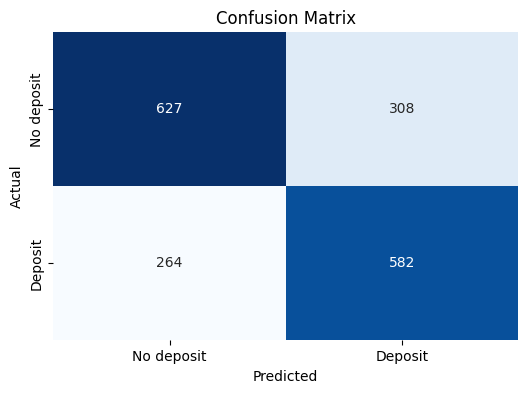


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.70      0.67      0.69       935
     Deposit       0.65      0.69      0.67       846

    accuracy                           0.68      1781
   macro avg       0.68      0.68      0.68      1781
weighted avg       0.68      0.68      0.68      1781

ROC-AUC: 0.7559025802455089


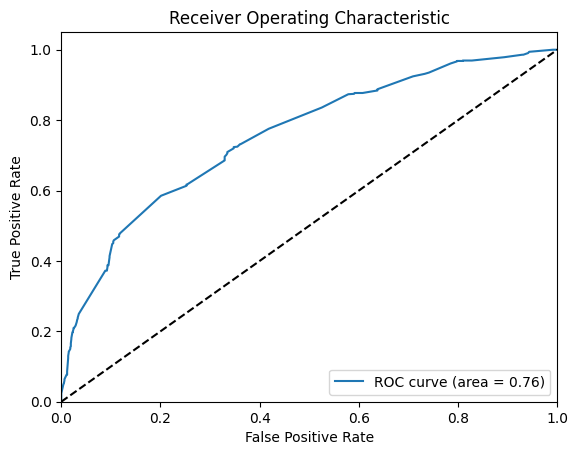

PR AUC: 0.7304058209759473


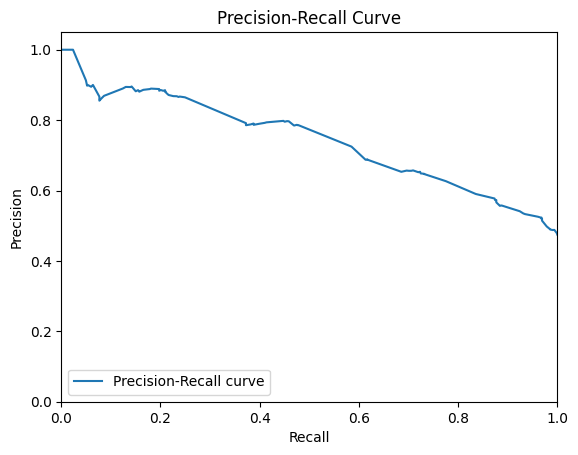

 62%|██████▏   | 8/13 [00:34<00:13,  2.69s/it]


Confusion Matrix:
 [[793 142]
 [317 529]]


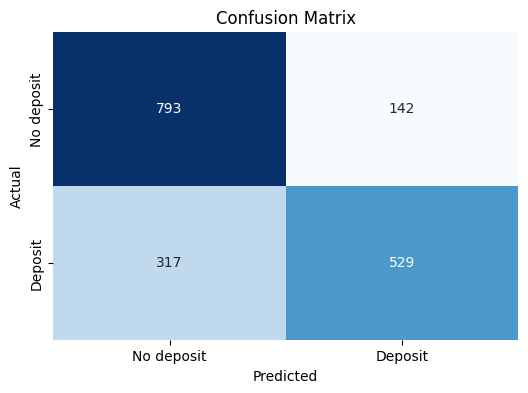


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.71      0.85      0.78       935
     Deposit       0.79      0.63      0.70       846

    accuracy                           0.74      1781
   macro avg       0.75      0.74      0.74      1781
weighted avg       0.75      0.74      0.74      1781

ROC-AUC: 0.8013666072489601


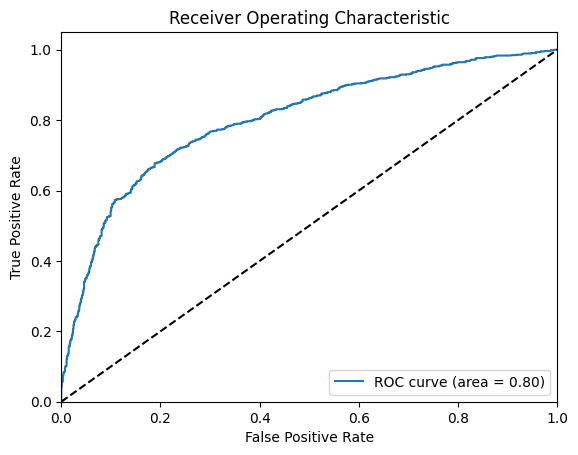

PR AUC: 0.7903840469833677


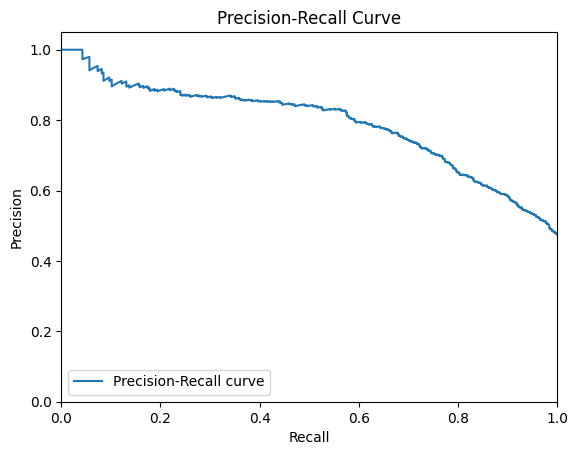

 69%|██████▉   | 9/13 [00:36<00:09,  2.42s/it]


Confusion Matrix:
 [[765 170]
 [301 545]]


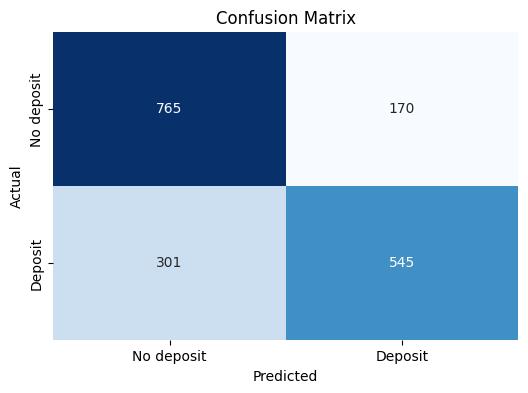


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.72      0.82      0.76       935
     Deposit       0.76      0.64      0.70       846

    accuracy                           0.74      1781
   macro avg       0.74      0.73      0.73      1781
weighted avg       0.74      0.74      0.73      1781

ROC-AUC: 0.7954551775578058


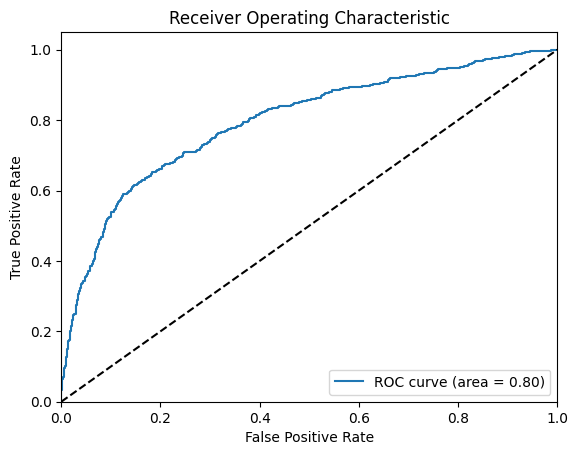

PR AUC: 0.7898091534529206


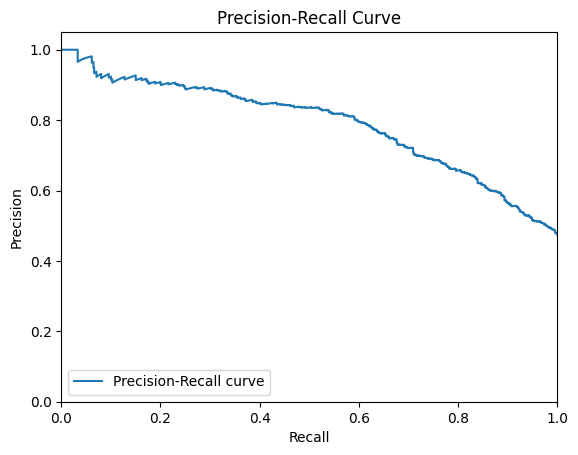

 77%|███████▋  | 10/13 [00:37<00:06,  2.04s/it]


Confusion Matrix:
 [[744 191]
 [297 549]]


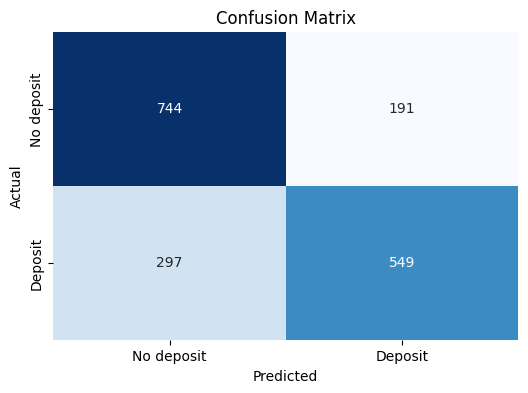


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.71      0.80      0.75       935
     Deposit       0.74      0.65      0.69       846

    accuracy                           0.73      1781
   macro avg       0.73      0.72      0.72      1781
weighted avg       0.73      0.73      0.72      1781

ROC-AUC: 0.7867662861405039


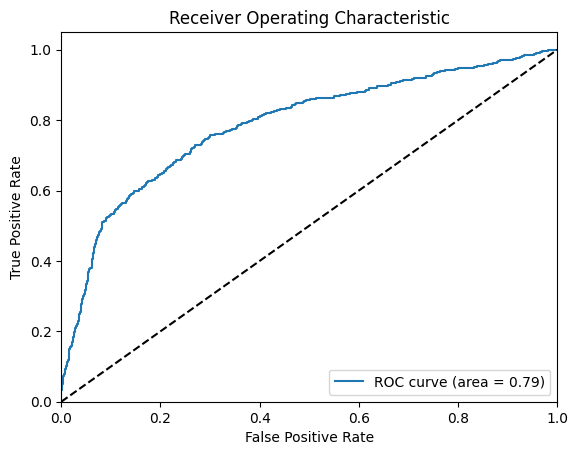

PR AUC: 0.7779720134504079


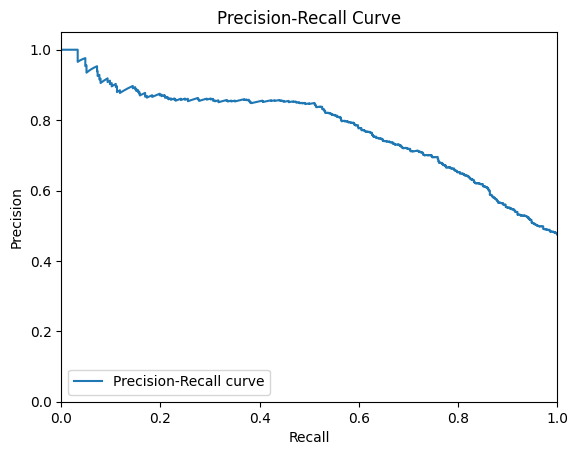

 85%|████████▍ | 11/13 [00:38<00:03,  1.64s/it]


Confusion Matrix:
 [[774 161]
 [296 550]]


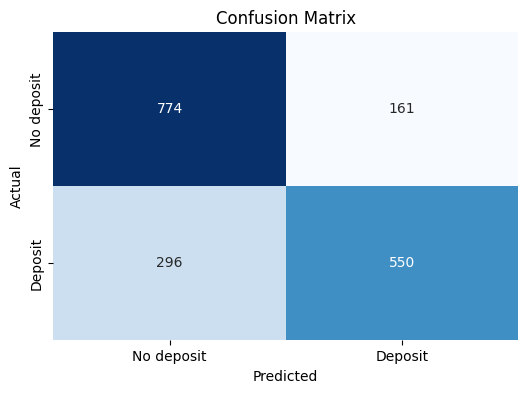


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.72      0.83      0.77       935
     Deposit       0.77      0.65      0.71       846

    accuracy                           0.74      1781
   macro avg       0.75      0.74      0.74      1781
weighted avg       0.75      0.74      0.74      1781

ROC-AUC: 0.8048570814528262


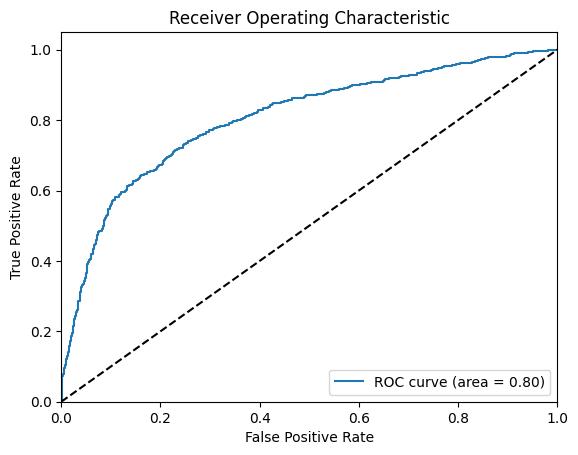

PR AUC: 0.7930373379558675


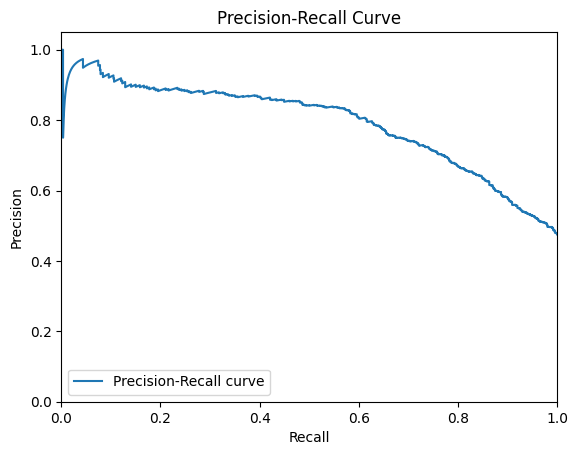

 92%|█████████▏| 12/13 [00:42<00:02,  2.64s/it]

[LightGBM] [Info] Number of positive: 3384, number of negative: 3738
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005598 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 781
[LightGBM] [Info] Number of data points in the train set: 7122, number of used features: 44
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.475147 -> initscore=-0.099492
[LightGBM] [Info] Start training from score -0.099492

Confusion Matrix:
 [[773 162]
 [294 552]]


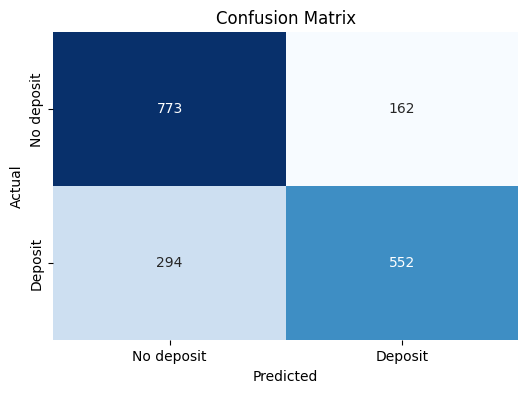


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.72      0.83      0.77       935
     Deposit       0.77      0.65      0.71       846

    accuracy                           0.74      1781
   macro avg       0.75      0.74      0.74      1781
weighted avg       0.75      0.74      0.74      1781

ROC-AUC: 0.7998027837827588


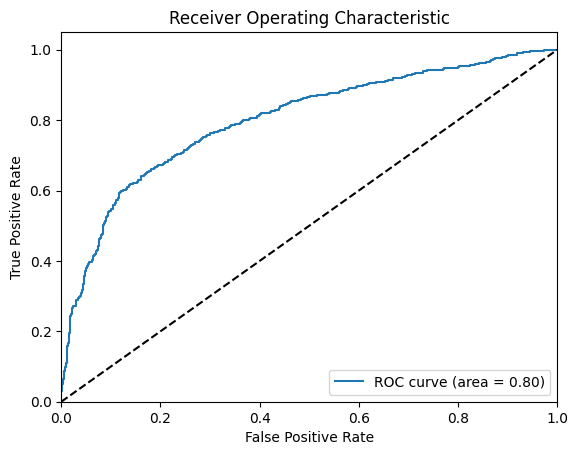

PR AUC: 0.7933629102589785


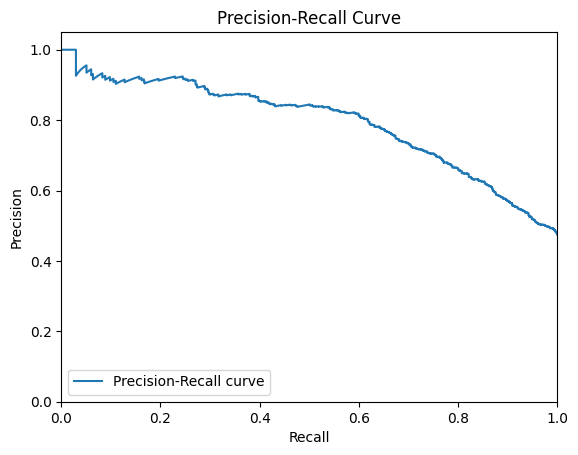

100%|██████████| 13/13 [00:44<00:00,  3.39s/it]


In [31]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['No deposit','Deposit']
                ,yticklabels=['No deposit','Deposit'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['No deposit','Deposit'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }


Confusion Matrix:
 [[866  69]
 [442 404]]


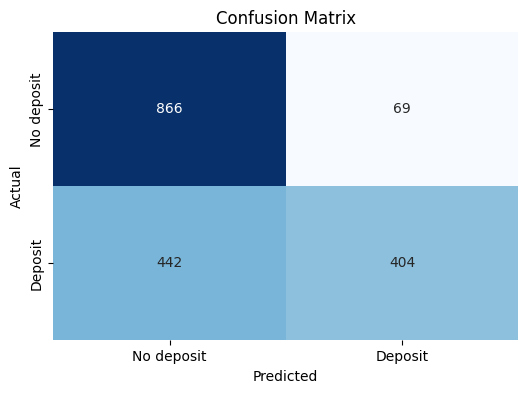


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.66      0.93      0.77       935
     Deposit       0.85      0.48      0.61       846

    accuracy                           0.71      1781
   macro avg       0.76      0.70      0.69      1781
weighted avg       0.75      0.71      0.70      1781

ROC-AUC: 0.7997926701305925


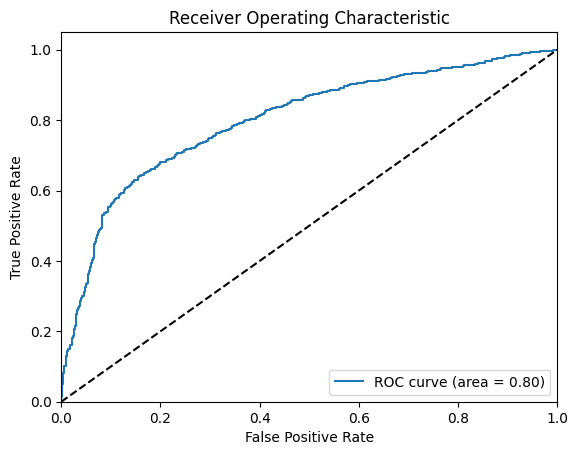

PR AUC: 0.7890805370850513


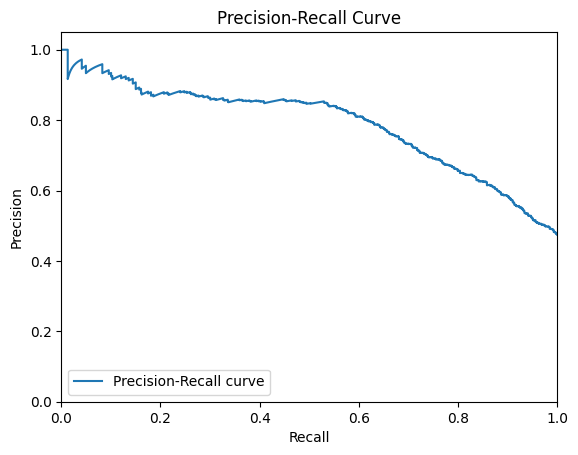

In [32]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['No deposit','Deposit']
            ,yticklabels=['No deposit','Deposit'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['No deposit','Deposit'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}


Confusion Matrix:
 [[735 200]
 [292 554]]


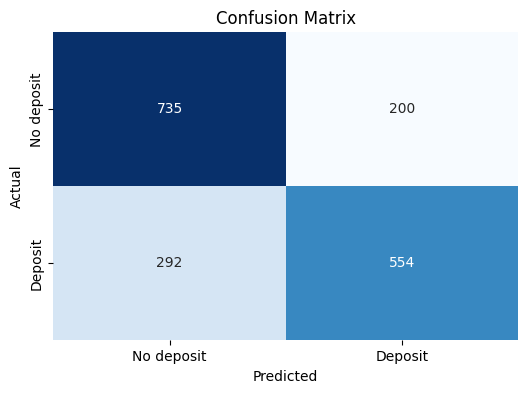


Classification Report:

              precision    recall  f1-score   support

  No deposit       0.72      0.79      0.75       935
     Deposit       0.73      0.65      0.69       846

    accuracy                           0.72      1781
   macro avg       0.73      0.72      0.72      1781
weighted avg       0.72      0.72      0.72      1781

ROC-AUC: 0.7717051617552243


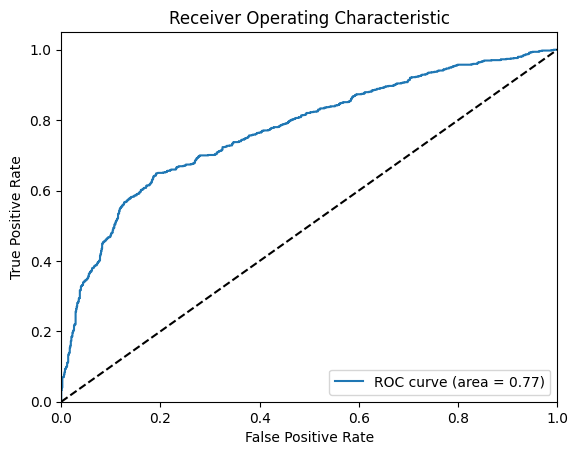

PR AUC: 0.7683575333995575


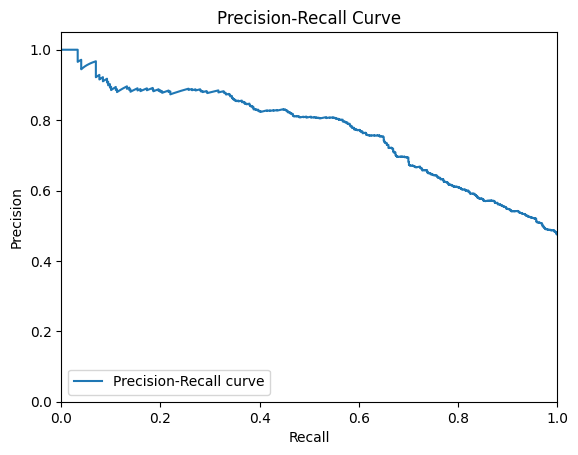

In [33]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(eval_metric='logloss', random_state=1),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['No deposit','Deposit']
            ,yticklabels=['No deposit','Deposit'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['No deposit','Deposit'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [34]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [35]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
LightGBM,0.831227,0.743964,0.879610,0.773109,0.747045,0.652482,0.807926,0.707692,0.827241,0.739610,0.799803,0.793363
CatBoost,0.822943,0.743403,0.872064,0.773558,0.735225,0.650118,0.797819,0.706487,0.818789,0.738963,0.804857,0.793037
Hist Gradient Boosting,0.825751,0.735542,0.873475,0.762238,0.740544,0.644208,0.801535,0.698270,0.821716,0.731195,0.795455,0.789809
Gradient Boosting,0.763830,0.742280,0.817537,0.788376,0.647459,0.625296,0.722625,0.697429,0.758320,0.736712,0.801367,0.790384
Random Forest,1.000000,0.726558,1.000000,0.737748,1.000000,0.658392,1.000000,0.695815,1.000000,0.723314,0.784574,0.772375
Stacking Classifier,0.762707,0.723751,0.800355,0.734748,0.666962,0.654846,0.727595,0.692500,0.758173,0.720471,0.771705,0.768358
XGBoost,0.892025,0.725997,0.933378,0.741892,0.832151,0.648936,0.879863,0.692308,0.889190,0.722329,0.786766,0.777972
SVC,0.780258,0.737226,0.859628,0.798107,0.642435,0.598109,0.735329,0.683784,0.773732,0.730605,0.778694,0.766872
Extra Trees,1.000000,0.701291,1.000000,0.701799,1.000000,0.645390,1.000000,0.672414,1.000000,0.698631,0.761000,0.747340
AdaBoost,0.683656,0.678832,0.664342,0.653933,0.675532,0.687943,0.669890,0.670507,0.683272,0.679266,0.755903,0.730406


<Axes: >

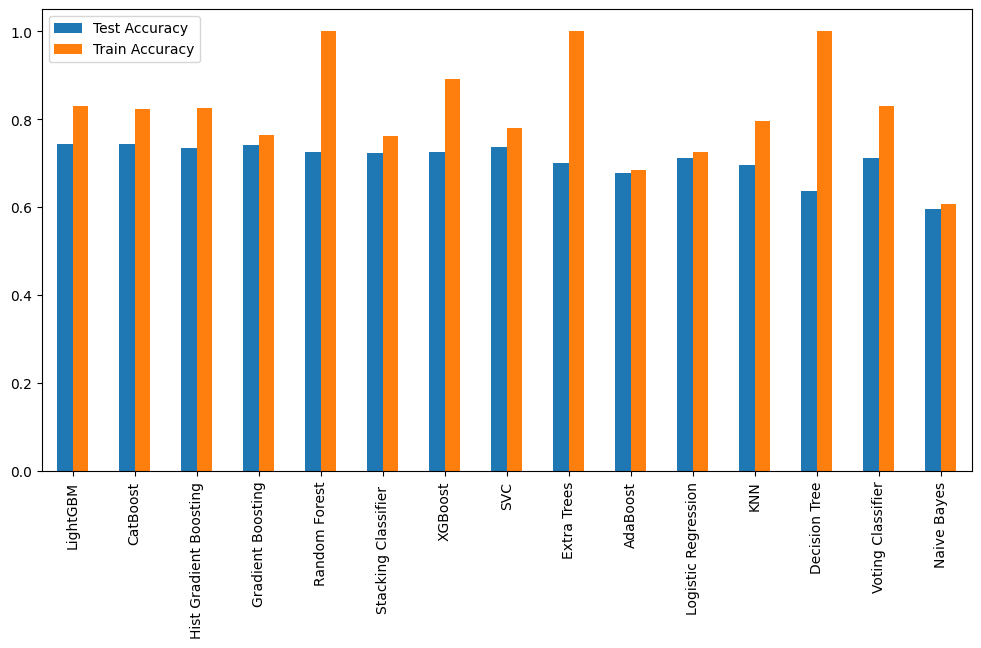

In [36]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

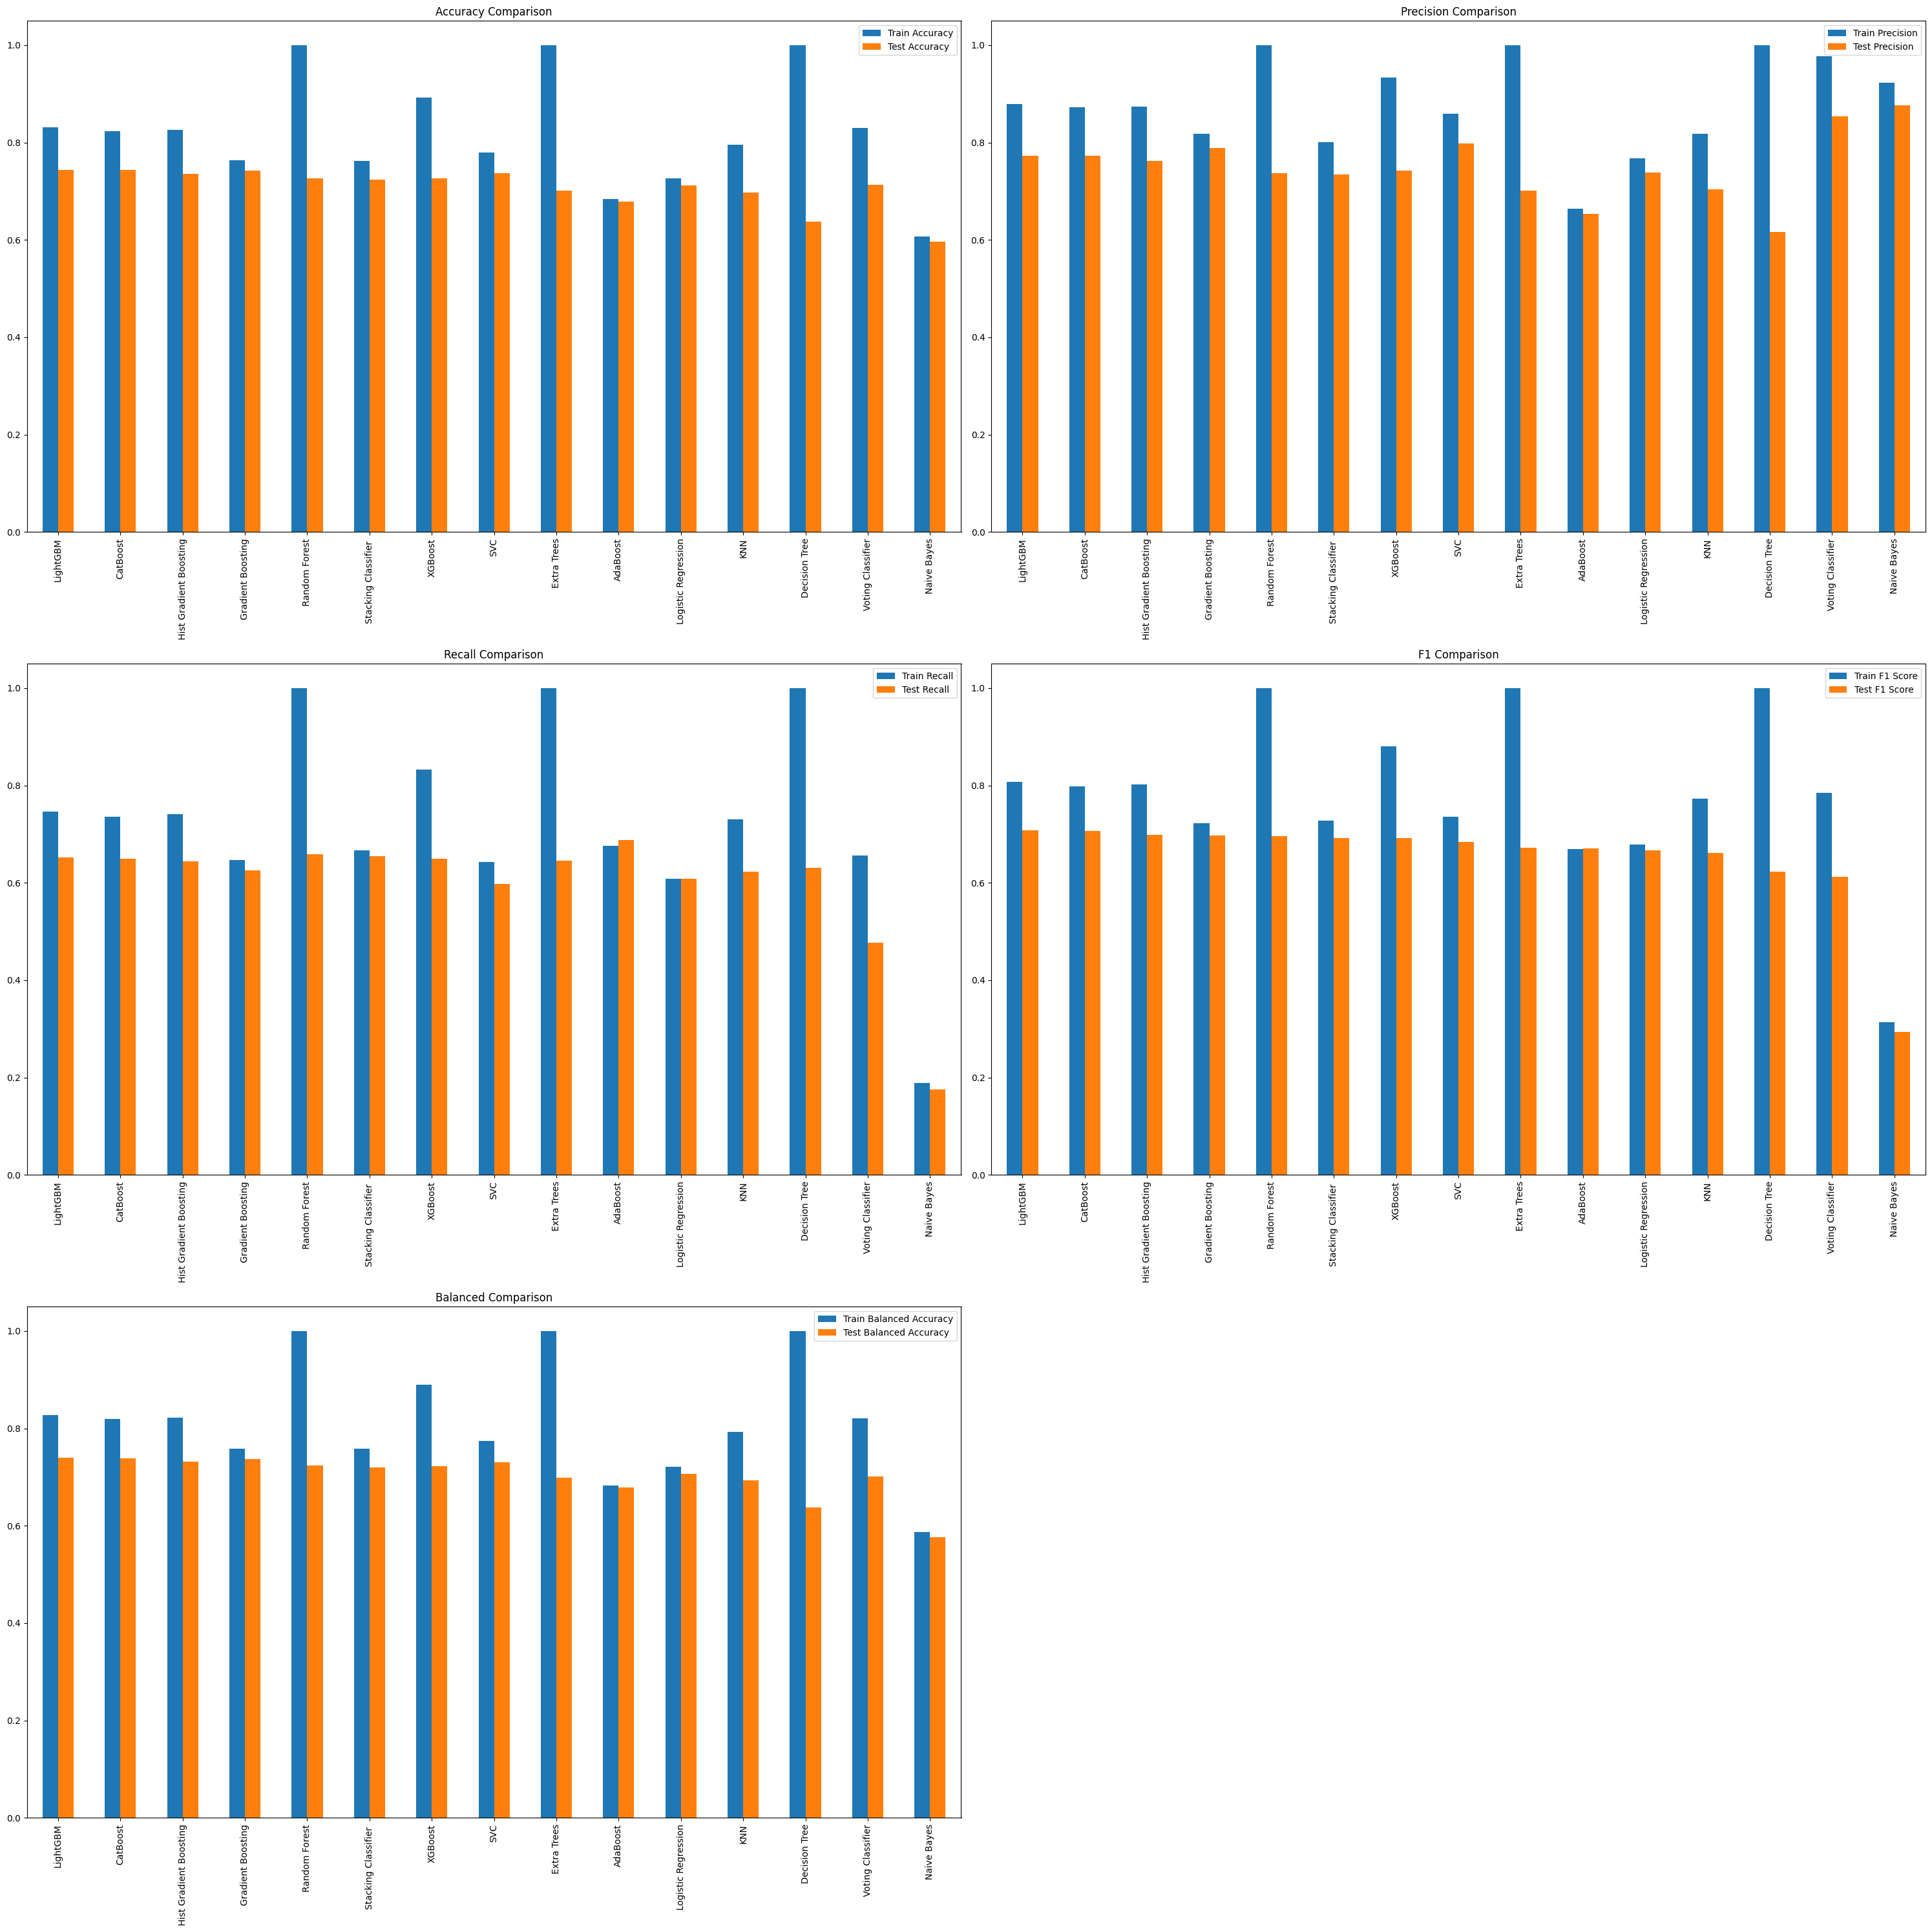

In [37]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()

**Note:** this table uses the test set to show how each model behaves with the default threshold. To **choose** and **tune** the model we use cross-validation on the training data only (next sections).

## 9. Model comparison with Cross-Validation (train data only)
5-fold stratified cross-validation on the training data. Main metric: **ROC-AUC** (the classes are almost balanced), with F1 and Accuracy next to it. (`SVC` is used without `probability=True` inside the CV only to save time.)

In [38]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.base import clone

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = {}
for name, model in tqdm(models.items()):
    m = SVC(random_state=1) if name == "SVC" else model
    cv = cross_validate(m, X_train, y_train, cv=skf, n_jobs=-1,
                        scoring={'roc_auc': 'roc_auc', 'f1': 'f1', 'accuracy': 'accuracy'})
    cv_rows[name] = {'CV ROC-AUC': cv['test_roc_auc'].mean(), 'CV F1': cv['test_f1'].mean(), 'CV Accuracy': cv['test_accuracy'].mean()}

cv_df = pd.DataFrame(cv_rows).T.sort_values('CV ROC-AUC', ascending=False)
cv_df

100%|██████████| 13/13 [00:55<00:00,  4.31s/it]


,CV ROC-AUC,CV F1,CV Accuracy
CatBoost,0.819708,0.724293,0.759478
Hist Gradient Boosting,0.812456,0.714590,0.749789
LightGBM,0.809200,0.711840,0.747824
Gradient Boosting,0.807899,0.704145,0.747404
XGBoost,0.800302,0.705816,0.736733
Random Forest,0.799713,0.706880,0.738697
SVC,0.795381,0.690995,0.743329
Logistic Regression,0.787121,0.672058,0.720442
Extra Trees,0.777772,0.689734,0.719602
AdaBoost,0.758349,0.668837,0.681269


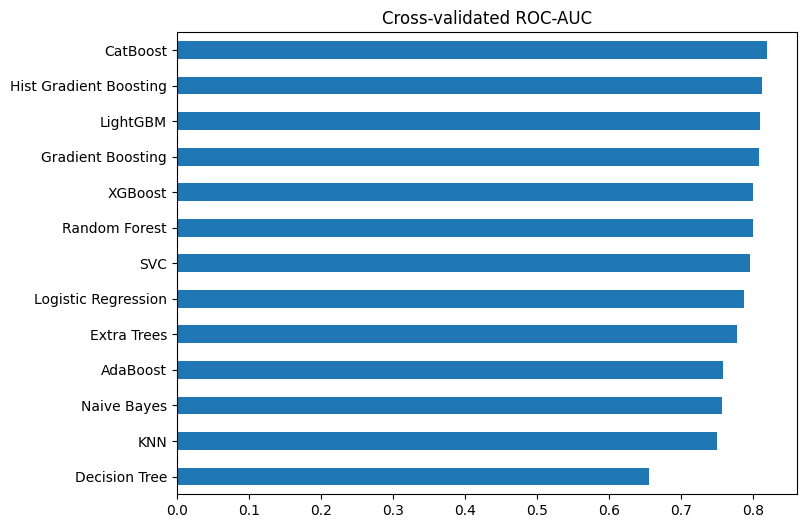

In [39]:
cv_df['CV ROC-AUC'].sort_values().plot.barh(figsize=(8, 6))
plt.title('Cross-validated ROC-AUC')
plt.show()

## 10. GridSearchCV on the best 3 models
The top 3 models of the cross-validation comparison are tuned with `GridSearchCV` (5-fold, metric ROC-AUC, training data only).

In [40]:
param_grids = {
    'Logistic Regression': {'C': [0.01, 0.1, 1, 10]},
    'KNN': {'n_neighbors': [5, 11, 21, 41], 'weights': ['uniform', 'distance']},
    'SVC': {'C': [0.5, 1, 5]},
    'Decision Tree': {'max_depth': [3, 5, 8], 'min_samples_leaf': [5, 20, 50]},
    'Naive Bayes': {'var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3]},
    'Random Forest': {'max_depth': [8, 12, None], 'min_samples_leaf': [1, 5, 10]},
    'Extra Trees': {'max_depth': [8, 12, None], 'min_samples_leaf': [1, 5, 10]},
    'AdaBoost': {'n_estimators': [50, 100, 200], 'learning_rate': [0.1, 0.5, 1.0]},
    'Gradient Boosting': {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [2, 3]},
    'Hist Gradient Boosting': {'learning_rate': [0.03, 0.1], 'max_depth': [3, None], 'max_iter': [100, 200]},
    'XGBoost': {'n_estimators': [100, 300], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.1]},
    'CatBoost': {'iterations': [300, 600], 'depth': [4, 6], 'learning_rate': [0.03, 0.1]},
    'LightGBM': {'n_estimators': [100, 300], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.1]},
}

top3 = cv_df.head(3).index.tolist()
print("Models to tune:", top3)

tuned = {}
summary = []
for name in top3:
    m = SVC(random_state=1) if name == "SVC" else models[name]
    grid = GridSearchCV(m, param_grids[name], cv=skf, scoring='roc_auc', n_jobs=-1)
    grid.fit(X_train, y_train)
    tuned[name] = grid
    print(f"\n{name}")
    print("  best_params_:", grid.best_params_)
    print("  best_score_ :", round(grid.best_score_, 4))
    summary.append([name, cv_df.loc[name, 'CV ROC-AUC'], grid.best_score_])

tuning_df = pd.DataFrame(summary, columns=['Model', 'Before tuning (CV ROC-AUC)', 'After tuning (best_score_)']).set_index('Model')
tuning_df

Models to tune: ['CatBoost', 'Hist Gradient Boosting', 'LightGBM']

CatBoost
  best_params_: {'depth': 6, 'iterations': 600, 'learning_rate': 0.03}
  best_score_ : 0.8199

Hist Gradient Boosting
  best_params_: {'learning_rate': 0.03, 'max_depth': None, 'max_iter': 200}
  best_score_ : 0.8146
[LightGBM] [Info] Number of positive: 3384, number of negative: 3738
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002952 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 781
[LightGBM] [Info] Number of data points in the train set: 7122, number of used features: 44
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.475147 -> initscore=-0.099492
[LightGBM] [Info] Start training from score -0.099492

LightGBM
  best_params_: {'learning_rate': 0.1, 'n_estimators': 100, 'num_leaves': 15}
  best_score_ : 0.8145


,Before tuning (CV ROC-AUC),After tuning (best_score_)
Model,,
CatBoost,0.819708,0.819861
Hist Gradient Boosting,0.812456,0.814565
LightGBM,0.809200,0.814531


**Why these parameters:** depth / leaf size / `C` control the complexity (overfitting vs underfitting); `learning_rate` and the number of trees trade off in boosting; `n_neighbors` controls the smoothness of KNN.

## 11. Final model and decision threshold
The best tuned model (highest `best_score_`) is refitted on the train data. The decision threshold is chosen on **cross-validated predictions of the training data** (the one that maximizes F1), not on the test set.

In [41]:
best_name = tuning_df['After tuning (best_score_)'].idxmax()
best_model = clone(tuned[best_name].best_estimator_)
print("Best model:", best_name, tuned[best_name].best_params_)

oof_proba = cross_val_predict(best_model, X_train, y_train, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = float(thr[np.argmax(f1s)])
print("Chosen threshold:", round(best_thr, 3))

best_model.fit(X_train, y_train)

Best model: CatBoost {'depth': 6, 'iterations': 600, 'learning_rate': 0.03}
Chosen threshold: 0.388


CatBoostClassifier(depth=6, iterations=600, learning_rate=0.03, random_state=1, verbose=0)

## 12. Final evaluation on the test set (used once)

--- Classification Report (tuned threshold) ---
              precision    recall  f1-score   support

  No deposit       0.77      0.70      0.73       935
     Deposit       0.70      0.76      0.73       846

    accuracy                           0.73      1781
   macro avg       0.73      0.73      0.73      1781
weighted avg       0.73      0.73      0.73      1781

Accuracy: 0.731 | ROC-AUC: 0.805 | PR-AUC: 0.792 | random PR-AUC: 0.475


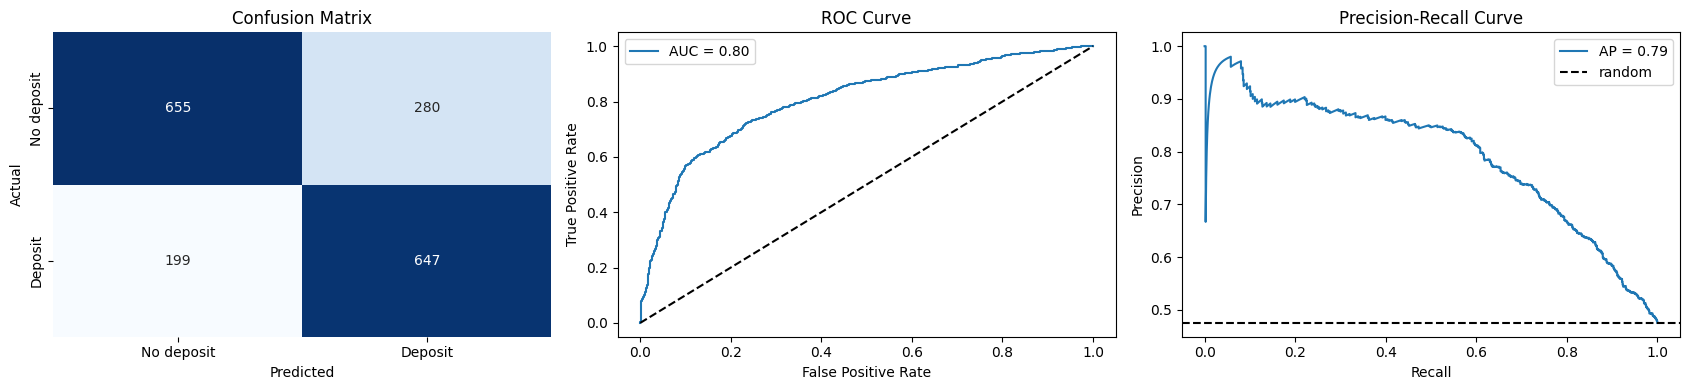

In [42]:
test_proba = best_model.predict_proba(X_test)[:, 1]
y_final = (test_proba >= best_thr).astype(int)

print("--- Classification Report (tuned threshold) ---")
print(classification_report(y_test, y_final, target_names=['No deposit', 'Deposit'], zero_division=0))

roc_auc = roc_auc_score(y_test, test_proba)
pr_auc = average_precision_score(y_test, test_proba)
print("Accuracy:", round(accuracy_score(y_test, y_final), 3), "| ROC-AUC:", round(roc_auc, 3), "| PR-AUC:", round(pr_auc, 3), "| random PR-AUC:", round(y_test.mean(), 3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
cm = confusion_matrix(y_test, y_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['No deposit', 'Deposit'], yticklabels=['No deposit', 'Deposit'])
axes[0].set_title('Confusion Matrix'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}'); axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('ROC Curve'); axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate'); axes[1].legend()

p_, r_, _ = precision_recall_curve(y_test, test_proba)
axes[2].plot(r_, p_, label=f'AP = {pr_auc:.2f}'); axes[2].axhline(y_test.mean(), color='k', linestyle='--', label='random')
axes[2].set_title('Precision-Recall Curve'); axes[2].set_xlabel('Recall'); axes[2].set_ylabel('Precision'); axes[2].legend()
plt.tight_layout()
plt.show()

In [43]:
tn, fp, fn, tp = cm.ravel()
print("=== Automatic interpretation of the results ===")
print(f"- Model: {best_name} | threshold: {best_thr:.2f}")
print(f"- Finds {tp} of {tp + fn} clients who subscribe (recall = {tp / (tp + fn):.0%}) and misses {fn}.")
print(f"- Of {tp + fp} clients predicted as 'will subscribe', {tp} really do (precision = {tp / max(tp + fp, 1):.0%}).")
print(f"- Accuracy = {accuracy_score(y_test, y_final):.1%} (always predicting the most frequent class would give {max(y_test.mean(), 1 - y_test.mean()):.1%}).")
print(f"- ROC-AUC = {roc_auc:.2f}, PR-AUC = {pr_auc:.2f} (random guessing = {y_test.mean():.2f}).")

=== Automatic interpretation of the results ===
- Model: CatBoost | threshold: 0.39
- Finds 647 of 846 clients who subscribe (recall = 76%) and misses 199.
- Of 927 clients predicted as 'will subscribe', 647 really do (precision = 70%).
- Accuracy = 73.1% (always predicting the most frequent class would give 52.5%).
- ROC-AUC = 0.80, PR-AUC = 0.79 (random guessing = 0.48).


**Interpretation**
- **Accuracy** must be compared with the "most frequent class" baseline (~53%): the gain over it shows how much the model really learns.
- **Recall (Deposit)** = how many future subscribers we find; **Precision (Deposit)** = how many of the clients we would call are really interested. For a marketing campaign, precision saves calls and recall saves missed sales; the threshold moves the balance.
- **Confusion matrix:** FP = calls wasted on uninterested clients, FN = interested clients we would not call.
- **ROC-AUC / PR-AUC** show the ranking quality over all thresholds.
- This is a binary problem, so no multiclass averaging is needed.
- **Without `duration`** the scores are lower than in notebooks that keep it, but they are honest: this is what we can predict *before* calling.

## 13. Conclusions
- `duration` was removed (leakage); missing values were handled without leakage (categories `unknown`, median from the train data only).
- The model was chosen with cross-validation, tuned with `GridSearchCV`, the threshold was chosen on training data, and the test set was used once.
- The Gradio app below uses the final model.
- Possible improvements: more feature engineering (e.g. previous contact yes/no from `pdays`), more tuning, cost-based threshold.

## 14. Gradio app

In [44]:
import gradio as gr

job_choices = sorted(X['job'].unique())
marital_choices = sorted(X['marital'].unique())
education_choices = sorted(X['education'].unique())
yes_no = ['no', 'yes']
contact_choices = sorted(X['contact'].unique())
month_choices = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
poutcome_choices = sorted(X['poutcome'].unique())


def predict_deposit(age, job, marital, education, default, balance, housing, loan,
                    contact, day, month, campaign, pdays, previous, poutcome):
    numbers = [age, balance, day, campaign, pdays, previous]
    if any(v is None for v in numbers):
        return ""

    input_data = pd.DataFrame([[
        age, job, marital, education, default, balance, housing, loan,
        contact, day, month, campaign, pdays, previous, poutcome
    ]], columns=X.columns)

    input_encoded = pd.get_dummies(input_data, columns=cat_cols)
    input_encoded = input_encoded.reindex(columns=X_encoded.columns, fill_value=0).astype(float)

    input_scaled = pd.DataFrame(scaler.transform(input_encoded), columns=X_encoded.columns)
    proba = best_model.predict_proba(input_scaled)[0, 1]

    answer = "Yes (Will Subscribe)" if proba >= best_thr else "No (Will Not Subscribe)"
    return f"{answer}  -  probability = {proba:.0%}"


demo = gr.Interface(
    fn=predict_deposit,
    inputs=[
        gr.Number(label="Age", value=59, precision=0),
        gr.Dropdown(job_choices, label="Job", value="admin."),
        gr.Dropdown(marital_choices, label="Marital", value="married"),
        gr.Dropdown(education_choices, label="Education", value="secondary"),
        gr.Dropdown(yes_no, label="Default", value="no"),
        gr.Number(label="Balance", value=2343),
        gr.Dropdown(yes_no, label="Housing", value="yes"),
        gr.Dropdown(yes_no, label="Loan", value="no"),
        gr.Dropdown(contact_choices, label="Contact", value="unknown"),
        gr.Number(label="Day", value=5, precision=0),
        gr.Dropdown(month_choices, label="Month", value="may"),
        gr.Number(label="Campaign", value=1, precision=0),
        gr.Number(label="Pdays", value=-1, precision=0),
        gr.Number(label="Previous", value=0, precision=0),
        gr.Dropdown(poutcome_choices, label="Poutcome", value="unknown"),
    ],
    outputs=gr.Textbox(label="Prediction Result"),
    title="Bank Deposit Prediction App",
    description="Enter client details to predict whether they will subscribe to a term deposit.",
)

demo.launch(share=True)   # share=True gives a public link when you run it in Colab

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0d97ddace0e5571da2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
